EJERCICIO 1: IMPLEMENTACIÓN TRANSFORMADA DISCRETA DE FOURIER

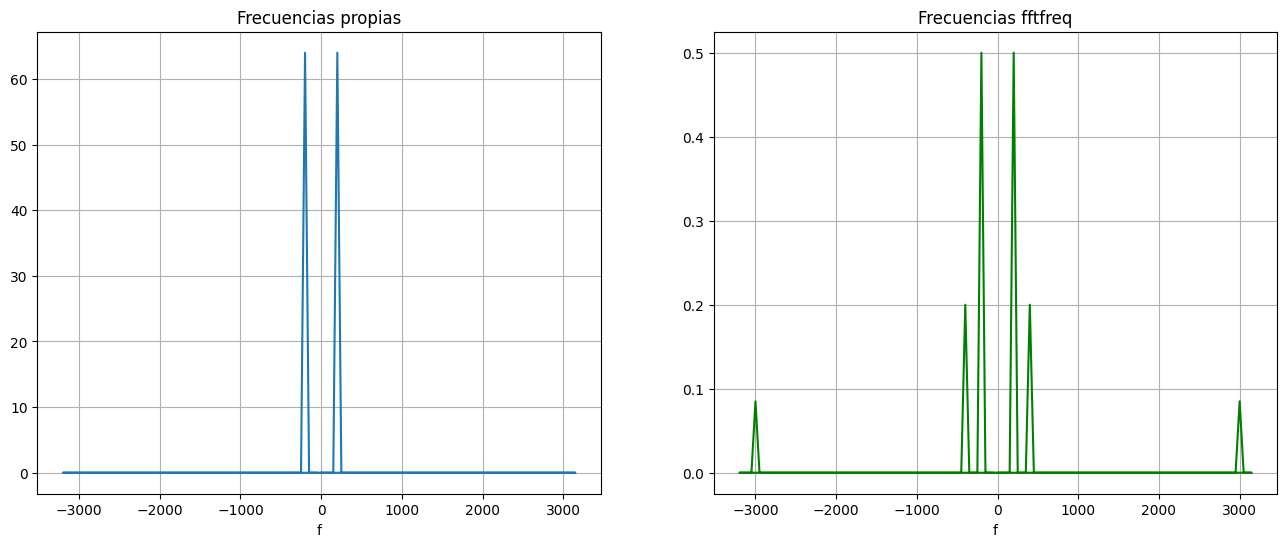

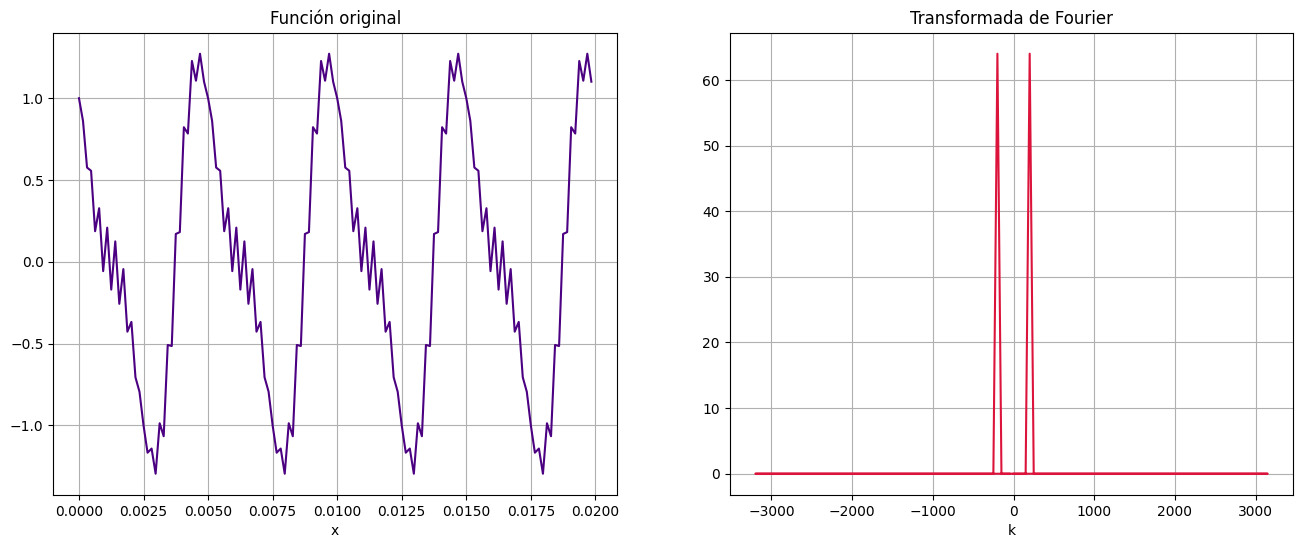

In [25]:
import numpy as np
import matplotlib.pylab as plt
from scipy.fftpack import fft, fftfreq

# Construcción de la señal
N = 128 # number of point in the whole interval
f = 200.0 #  frequency in Hz
dt = 1 / (f * 32 ) #32 samples per unit frequency
t = np.linspace( 0, (N-1)*dt, N)
y = np.cos(2 * np.pi * f * t) - 0.4 * np.sin(2 * np.pi * (2*f) * t )+ 0.17*np.sin(2 * np.pi * (15*f) * t )

# 1) implemente de la transformada de fourier discreta
def Fourier_propia(fun,len):
  Fr = np.zeros(len, dtype="complex") #x_k
  n = np.arange(len)

  for k in range(len):
    Fr[k] = np.sum( fun[:] * np.exp(- (0+1j) * 2 * np.pi * k * n[:] / len) )

  return np.real(Fr) # Tomo solo la parte real

# 2) Genere el arreglo de las frecuencias (ver documentación de fftfreq):
def Frecuencias_propia(dt, len):
  if len % 2 == 0: # Si N es par
    frecuencias = np.zeros(len)
    frecuencias_p1 = np.arange(len/2)          #parte 1, son positivos desde el cero hasta n/2 -1
    frecuencias_p2 = -np.arange(len/2)[::-1]-1 #parte 2, son negativos desde -n/2 hasta -1
    frecuencias[:int(len/2)] = frecuencias_p1 / (dt * len)
    frecuencias[int(len/2):] = frecuencias_p2 / (dt * len)

  if len % 2 == 1: # Si N es impar
    frecuencias = np.zeros(len-1)
    frecuencias_p1 = np.arange((len-1)/2)          #parte 1, son positivos desde el cero hasta (n-1)/2
    frecuencias_p2 = -np.arange((len-1)/2)[::-1]-1 #parte 2, son negativos desde -(n-1)/2 hasta -1
    frecuencias[:int((len-1)/2)] = frecuencias_p1 / (dt * len)
    frecuencias[int((len-1)/2):] = frecuencias_p2 / (dt * len)

  return frecuencias
# 3) Haga una gráfica comparando método propio con implementación de scipy.fftpack.fft
fft_x = fft(y) / N # FFT Normalized
freq = fftfreq(N, dt) # Recuperamos las frecuencias

fig1, (ax1,ax2) = plt.subplots(1,2, figsize=(16,6))

ax1.plot(Frecuencias_propia(dt, N), np.abs(Fourier_propia(y, N)))
ax1.grid(True)
ax1.set_xlabel("f")
ax1.set_title("Frecuencias propias")

ax2.plot(freq, np.abs(fft_x), color="green")
ax2.grid(True)
ax2.set_xlabel("f")
ax2.set_title("Frecuencias fftfreq")

plt.show()

# Gráfica prueba
fig, (ax1,ax2) = plt.subplots(1,2, figsize=(16,6))

ax1.plot(t,y, color="indigo")
ax1.set_xlabel("x")
ax1.set_title("Función original")
ax1.grid(True)


ax2.plot(freq,np.abs(Fourier_propia(y, N)), color="crimson")
ax2.set_xlabel("k")
ax2.set_title("Transformada de Fourier")
ax2.grid(True)

plt.show()

EJERCICIO 2: FILTRO DE FOURIER

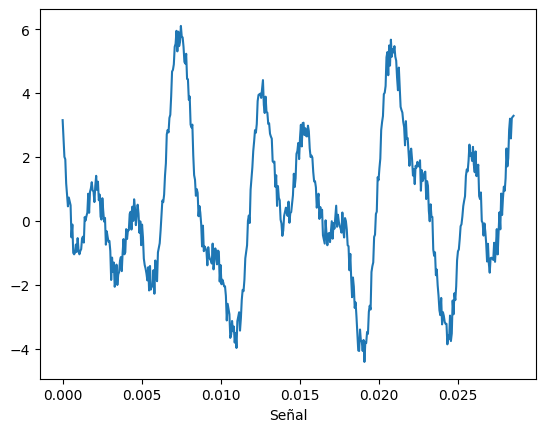

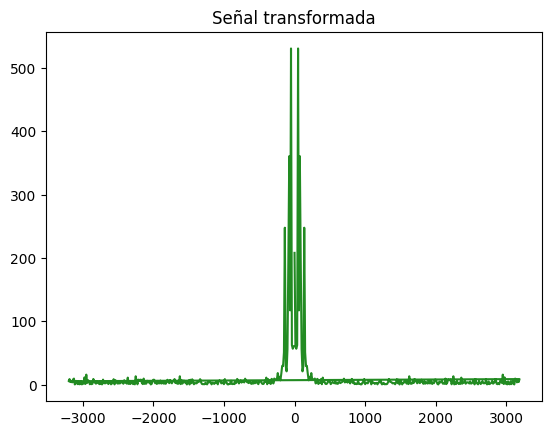

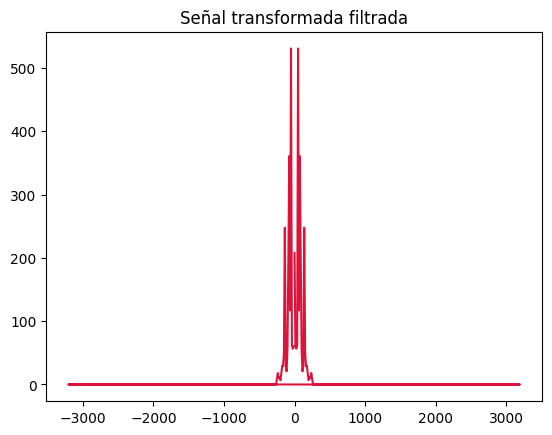

/usr/local/lib/python3.13/dist-packages/matplotlib/cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/usr/local/lib/python3.13/dist-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


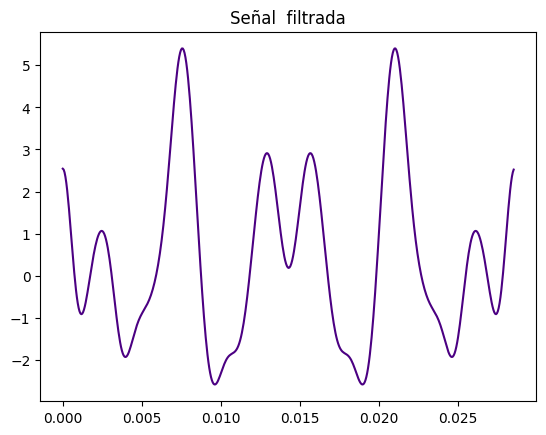

In [72]:
import numpy as np
import matplotlib.pylab as plt
from scipy.fftpack import fft, fftfreq, ifft

# 1) Almacene los datos de signal.dat. La columna 1 es el tiempo y la columna 2 es su señal f(t).
#Grafique su señal en función del tiempo.
ruta = "/content/drive/MyDrive/Herramientas Computacionales/S4/signal.dat"
# ruta_loc = "signal.dat"
archivo = np.genfromtxt(ruta, delimiter=",")
tiempo = archivo[:,0]
señal = archivo[:,1]
tamaño = len(tiempo)
dt1 = 1 / (6400)

plt.plot(tiempo, señal)
plt.xlabel("Tiempo")
plt.xlabel("Señal")
plt.show()

# 2) Use fftfreq (BONO si usa su implementación propia) y haga una gráfica de su transformada de fourier en función de las frecuencias.
frecuencia = Frecuencias_propia(dt1, tamaño)
transformada = Fourier_propia(señal, tamaño)

plt.plot(frecuencia, np.abs(transformada), color = "forestgreen")
plt.title("Señal transformada")
plt.show()

# 3) Haga un filtro pasa bajos que le permita filtrar el ruido de la señal del punto 1. #
#Use la gráfica de la transformada de fourier del punto 3 para determinar un valor apropiado de la frecuencia de corte que debe usar para filtrar dicho ruido de alta frecuencia.
for l in range(tamaño):
  if (frecuencia[l] > 250) or (frecuencia[l] < -250):
    transformada[l] = 0

plt.plot(frecuencia, np.abs(transformada), color = "crimson")
plt.title("Señal transformada filtrada")
plt.show()

# 4) Grafique la señal filtrada
señal_filtrada = ifft(transformada,tamaño)

plt.plot(tiempo, señal_filtrada, color = "indigo")
plt.title("Señal  filtrada")
plt.show()

EJERCICIO 3 (hagánlo cuando terminen los de transformada de Fourier 2D): FILTROS VIOLIN-TROMPETA

In [ ]:
import numpy as np
import matplotlib.pylab as plt
from scipy.fftpack import fft, fftfreq

# 1) Almacene los datos de violin.wav (use wav.read('violin.wav')).
#Grafique su señal en función del tiempo y guarde dicha gráfica.

# 2) Use fftfreq (BONO si usa su implementación propia) y haga una gráfica de su transformada de fourier en función de las frecuencias.

# 3) Haga un filtro que elimine el pico principal. Grafique su señal filtrada.
#Escuche (OJO con el volumen!) sus datos filtrados.
#Repita lo anterior haciendo un filtro pasaaltos y uno pasabajos.

#NOTA: para el manejo de archivos .wav mire la documentacion de python de input-output en https://docs.scipy.org/doc/scipy-0.14.0/reference/io.html)

# 4) repita lo anterior para trumpet.wav que es la señal correspondiente al sonido de una trompeta tocando la misma nota que el violín del puntos anterior.


EJERCICIO 4: FILTRO RUIDO PERIÓDICO IMAGEN 2D

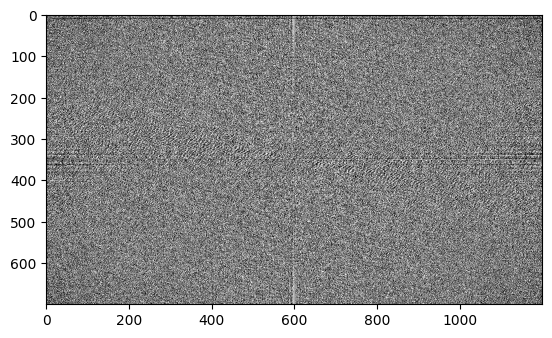

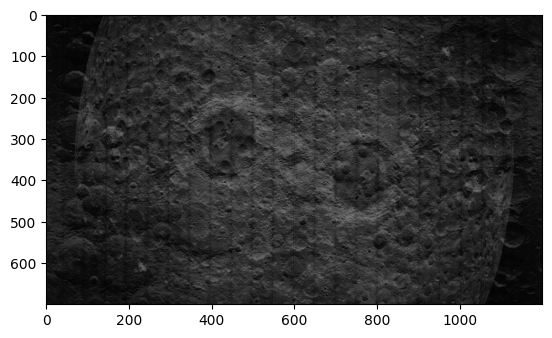

In [91]:
import numpy as np
import matplotlib.pylab as plt
from scipy.fftpack import fft, fftfreq, fft2, ifft2, fftshift

# 1) Almacene los datos de la imagen (use imread: https:/req/matplotlib.org/stable/apireq/_as_gen/matplotlib.pyplot.imread.html)
dir_im = "/content/drive/MyDrive/Herramientas Computacionales/S4/moon.jpg"
loc_im = "moon.jpg"

img_data = plt.imread(dir_im)

# 2) Use la librería de scipy de transformada de fourier en 2d y la trasnformada inversa
#(https://docs.scipy.org/dreqoc/scipy/reference/generated/scipy.fft.fft2.html)
#para hacer un código que filtre el ruido periodico que tiene la imagen de la luna.
transf_2D = np.real(fftshift(fft2(img_data)))
transf_2D[10,10:] = 0

plt.imshow(transf_2D, cmap='gray', vmin=0, vmax=255)
plt.show()

#3) haga una gráfica de la imagen filtrada y guárdela en LunaFiltrada.png
img_filtrada = np.real(ifft2(transf_2D))
plt.imshow(img_filtrada, cmap='gray', vmin=0, vmax=255)
plt.show()
#imagen: https://blogs.3ds.com/simulia/wp-content/uploads/sites/18/2019/07/NASA_Moon.jpg

EJERCICIO 5: FASE Y MAGNITUD

In [ ]:
#Recupere la imagen original a partir de la fase y la amplitud de la transformada de fourier (archivos amplitude.dat y phase.dat).
#Recuerde que la transformada de fourier tiene una parte real y una imaginaria
#y recuerde tambien que un numero complejo se puede escribir a partir de la fase y la magnitud que son los datos que usted tiene
#(http://webpages.ursinus.edu/lriley/ref/complex/node1.html)


#1)Descargue los datos de fase y magnitud
#2) construya la transformada de fourier
#3) Obtenga la imagen haciendo la transformada inversa
